In [1]:
from tensorflow import keras
from sklearn.model_selection import train_test_split

(train_input, train_target), (test_input, test_target) =\
    keras.datasets.fashion_mnist.load_data()
train_scaled = train_input/255.0
train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [2]:
# 모델을 만드는 함수
def model_fn(a_layer=None):
    model = keras.Sequential()
    model.add(keras.layers.Flatten(input_shape=(28, 28)))
    model.add(keras.layers.Dense(100, activation='relu'))
    if a_layer:
        model.add(a_layer)
    model.add(keras.layers.Dense(10, activation='softmax'))
    return model

In [3]:
model = model_fn()
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=5, verbose=0)

`verbose=0`의 의미'

verbose 매개변수는 훈련 과정 출력을 조절한다. 기본값은 1로 epoch마다 진행 막대와 함께 손실 등의 지표가 출력된다.

2로 바꾸면 진행 막대를 빼고 출력한다.

verbose=0은 훈련과정을 나타내지 않는다.



In [5]:
print(history.history.keys())

dict_keys(['accuracy', 'loss'])


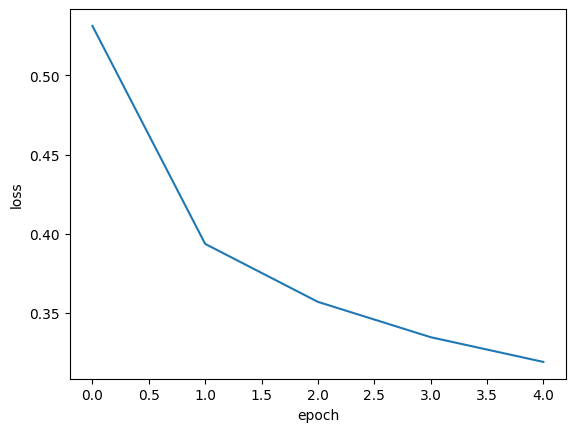

In [6]:
# loss 시각화
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

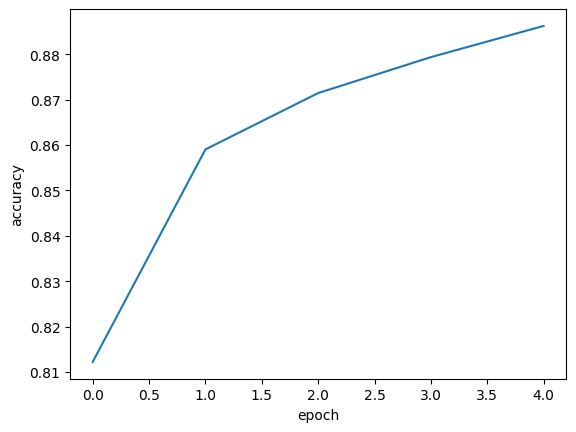

In [7]:
# accuracy 시각화
plt.plot(history.history['accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

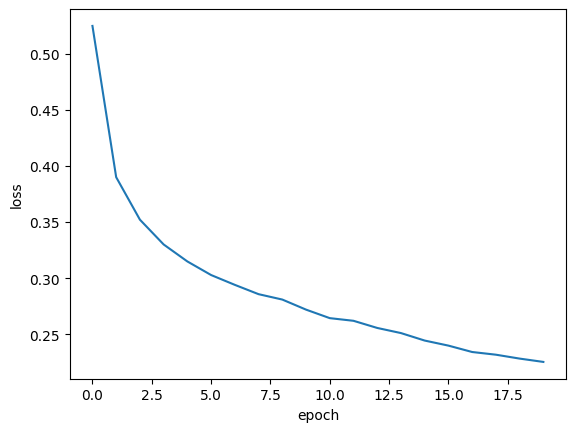

In [8]:
# epoch=20으로 늘린 모델
model = model_fn()
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0)
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

인공 신경망 모델이 최적화하는 대상은 정확도가 아닌 손실 함수이다.

따라서 모델이 잘 훈련되었는지 판단하려면 손실 함수의 값을 확인하는 것이 더 낫다.

In [9]:
model = model_fn()
model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))

In [10]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


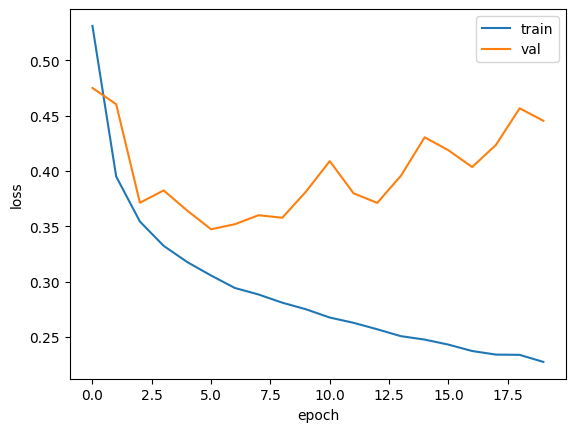

In [11]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

초기 val_loss가 감소하다가 5번째 epoch만에 다시 상승

train_loss는 꾸준히 감소하기 때문에 전형적인 과대적합 모델이 된다.

val_loss가 상승하는 시점을 가능한 늦추면 손실이 줄어들 뿐만 아니라 정확도도 증가할 것

Optimizer 하이퍼파라미터를 조정하여 과대적합 완화시켜보기

RMSprop -> Adam 순으로 Optimizer 테스트 해보기

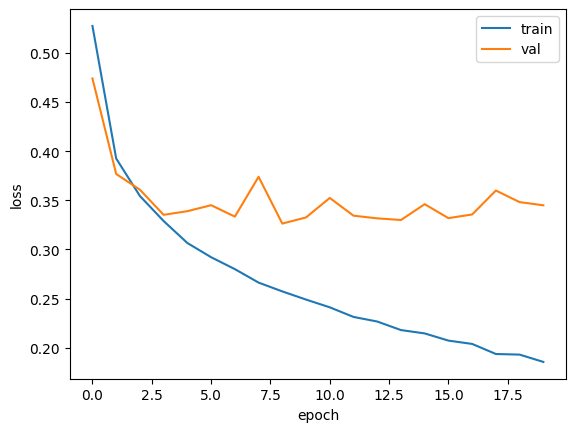

In [12]:
model = model_fn()
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

val_loss 그래프에 여전히 요동이 남아있지만 10번째 epoch까지 전반적인 감소 추세가 보인다.

드롭아웃(Dropout)은 훈련과정에서 층에 있는 일부 뉴런을 랜덤하게 꺼서(즉 뉴런의 출력을 0으로 만들어) 과대적합을 막는다.

뉴런은 랜덤하게 드롭아웃되고 얼마나 많은 뉴런을 드롭할지는 또 다른 하이퍼파라미터이다.

**이전 층의 일부 뉴런이 랜덤하게 꺼지면 특정 뉴런에 과대하게 의존하는 것을 줄일 수 있고 모든 입력에 대해 주의를 기울여야한다.**

In [13]:
model = model_fn(keras.layers.Dropout(0.3))
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

드롭아웃층은 훈련되는 모델 파라미터가 없다. 또한 입력과 출력의 크기가 같다.

일부 뉴런의 출력을 0으로 만들지만 전체 출력 배열의 크기를 바꾸지는 않는다.

**평가나 예측을 수행할 때는 드롭아웃을 적용하면 안된다!!**

tensorflow와 keras는 모델을 평가와 예측에 사용할 때는 자동으로 드롭아웃을 적용하지 않는다.

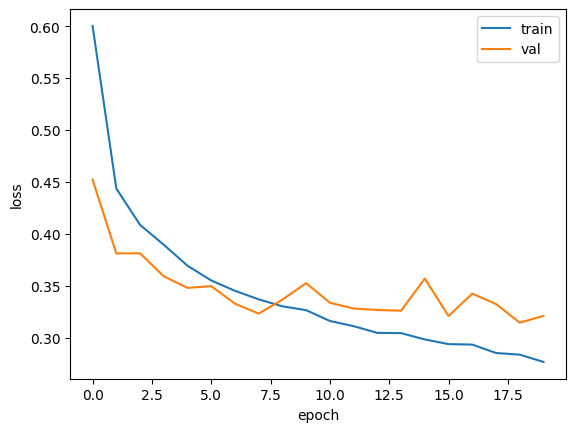

In [14]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=20, verbose=0, validation_data=(val_scaled, val_target))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

10번째 epoch 정도에서 val_loss 감소가 멈추지만 크게 상승하지않고 어느정도 유지되고 있다.

epoch를 10으로 하고 다시 훈련

In [16]:
# 모델 저장과 복원
model = model_fn(keras.layers.Dropout(0,3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_scaled, train_target, epochs=10, verbose=0,
                    validation_data=(val_scaled, val_target))

In [17]:
# 모델 저장
model.save('model-whole.keras')

In [18]:
# 훈련된 모델의 파라미터만 저장하는 save_weights() 메서드
model.save_weights('model.weights.h5')

In [19]:
!ls -al model*

-rw-r--r-- 1 root root 971928 Dec 21 05:53 model.weights.h5
-rw-r--r-- 1 root root 974759 Dec 21 05:53 model-whole.keras


두가지 실험
1. 훈련을 하지않은 새로운 모델을 만들고 model-weights.h5 파일에서 훈련된 모델 파라미터 사용
2. model-whole.keras 파일에서 새로운 모델을 만들어서 바로 사용

In [20]:
model = model_fn(keras.layers.Dropout(0.3))
model.load_weights('model.weights.h5')

훈련하지 않은 새로운 모델을 만들고 이전에 저장했던 모델 파라미터를 적재

*load_weights() 메서드를 사용하기 위해서는 save_weights() 메서드로 저장했던 모델과 정확히 같은 구조를 가져야 함.*

In [21]:
import numpy as np
val_labels = np.argmax(model.predict(val_scaled), axis=-1)
print(np.mean(val_labels == val_target))

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
0.8815


argmax() 함수는 배열에서 가장 큰 값의 인덱스를 반환한다.

argmax() 함수의 axis=-1은 배열의 마지막 차원을 따라 최댓값을 고른다.

In [23]:
model = keras.models.load_model('model-whole.keras')
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8812 - loss: 0.3303


[0.3317347764968872, 0.8815000057220459]

콜백(Callback)은 훈련 과정 중간에 어떤 작업을 수행할 수 있게 하는 객체로 keras.callbacks 패키지 아래에 있는 클래스이다.

fit() 메서드의 callbakcs 매개변수에 리스트로 전달하여 사용한다.

ModelCheckpoint 콜백은 기본적으로 에포크마다 모델을 저장한다.

save_best_only=True 매개변수를 지정하여 가장 낮은 val loss를 만드는 모델을 저장할 수 있다.

In [24]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

checkpoint_cb = keras.callbacks.ModelCheckpoint('best-model.keras', save_best_only=True)

model.fit(train_scaled, train_target, epochs=20, verbose=0,
          validation_data=(val_scaled, val_target),
          callbacks=[checkpoint_cb])

In [25]:
model = keras.models.load_model('best-model.keras')
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8845 - loss: 0.3193


[0.3211809992790222, 0.8843333125114441]

과대적합이 시작되기 전에 훈련을 미리 중지하는 것을 조기종료(Early stopping)이라고 한다.

EarlyStopping 콜백의 patience 매개변수는 val 점수가 향상되지 않더라도 참을 에포크 횟수로 지정한다.

또한 restore_best_weights 매개변수를 True로 지정하면 가장 낮은 val loss를 낸 모델 파라미터로 되돌린다.

In [27]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

checkpoint_cb = keras.callbacks.ModelCheckpoint('best-model.keras', save_best_only=True)
early_stopping_cb = keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)

model.fit(train_scaled, train_target, epochs=20, verbose=0,
          validation_data=(val_scaled, val_target),
          callbacks=[checkpoint_cb, early_stopping_cb])

In [28]:
# 몇번째 epoch에서 훈련이 중지되었을까?
print(early_stopping_cb.stopped_epoch)

10


10번째 epoch에서 훈련이 중지. 최상의 모델은 9번째 모델일 것.

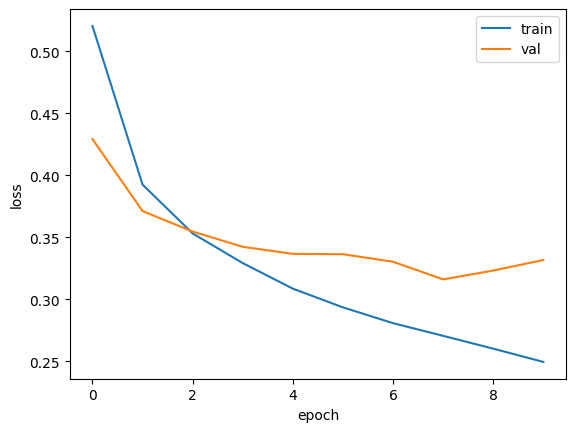

In [29]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [30]:
model.evaluate(val_scaled, val_target)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8847 - loss: 0.3218


[0.3229491114616394, 0.8824166655540466]